In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score, confusion_matrix, f1_score
import numpy as np

In [2]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

X, y = load_breast_cancer(return_X_y=True, as_frame=True)

In [9]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
scaler = StandardScaler().fit(X = X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

In [8]:
clf = LogisticRegression(class_weight='balanced', max_iter=10000)
clf.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm t

In [13]:
scores = clf.predict_proba(X_test)[:,1]
scores[:5]

array([5.30936673e-08, 9.99979217e-01, 4.99336196e-03, 4.53022117e-01,
       4.50292655e-10])

In [14]:
print("PR-AUC:", average_precision_score(y_test, scores))

PR-AUC: 0.9970652078135953


average_precision_score summarizes the Precision-Recall curve into a single metric by calculating the weighted mean of precisions achieved at each threshold. The weight is defined as the increase in recall from the previous threshold.

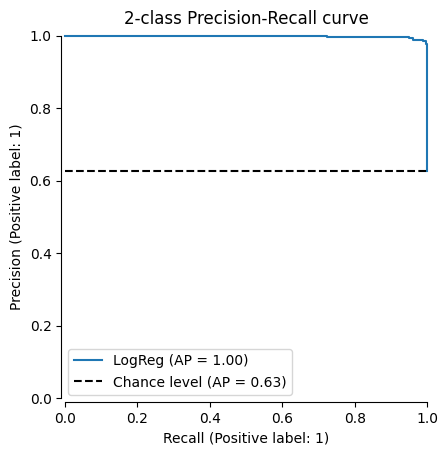

In [22]:
from sklearn.metrics import PrecisionRecallDisplay

display = PrecisionRecallDisplay.from_estimator(
    clf, X_train, y_train, name="LogReg", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

In [23]:
# choose a threshold instead of the default 0.5
p, r, th = precision_recall_curve(y_train, clf.predict_proba(X_train)[:,1])
f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
best = th[f1.argmax()]
print("best threshold:", best, "F1:", f1_score(y_test, scores >= best), "Base F1:",f1_score(y_test, scores >= 0.5) )

best threshold: 0.4604528725105927 F1: 0.9645390070921985 Base F1: 0.9645390070921985


In [24]:
p[0], r[0], th[0]

(np.float64(0.6263736263736264),
 np.float64(1.0),
 np.float64(9.559611792996207e-18))

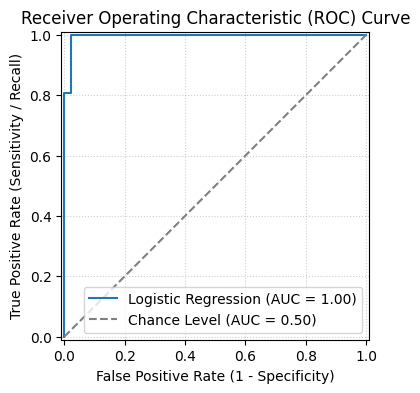

In [25]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# 4. Plot the ROC Curve
fig, ax = plt.subplots(figsize=(5, 4))

# Plot the model's curve (automatically calculates TPR, FPR, and AUC)
RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=ax, name="Logistic Regression")

# Plot the 0.50 random guessing chance level line
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance Level (AUC = 0.50)")

# Aesthetics and formatting
ax.set_title("Receiver Operating Characteristic (ROC) Curve")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")
ax.legend(loc="lower right")
ax.grid(True, linestyle=":", alpha=0.6)

# Display the plot
plt.show()

In [26]:
confusion_matrix(y_test, scores > 0.5)

array([[41,  1],
       [ 4, 68]])

In [ ]:
# with cross validation

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

pipe = Pipeline([("scale", StandardScaler()),
                 ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])

cv = StratifiedKFold(5, shuffle=True, random_state=42)
oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]

p, r, th = precision_recall_curve(y_tr, oof)
f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
best = th[f1.argmax()]

pipe.fit(X_tr, y_tr)
scores = pipe.predict_proba(X_te)[:, 1]
print("PR-AUC:", average_precision_score(y_te, scores))
print("F1 at best threshold:", f1_score(y_te, scores >= best))